In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pymc
from magnus import NSFeas
from helpers import Trellis, Corner, train_surrogate, generate_sobol_points, parity_plot
from plotstyle import setup, save, FIGURES_DIR
setup()

In [2]:
# Helpers
def theta_nominal():
    T_REF = 328.15
    k_1_ref = 8.84e-3 * 60 * 0.5 # 1/min
    k_2_ref = k_1_ref / 8
    theta_1 = k_1_ref * np.exp(E_1 / (R_GAS * T_REF))
    theta_2 = k_2_ref * np.exp(E_2 / (R_GAS * T_REF))

    return theta_1, theta_2

In [3]:
# Global Constants
E_1 = 48_000 # J/mol (activation energy first reaction)
E_2 = 55_000 # J/mol (activation energy second reaction)
R_GAS = 8.314 # J/K/mol
T_LO, T_HI, TAU_LO, TAU_HI = 298.15, 353.15, 2, 30 # K, K, min, min
DCB_FRACTION_CAP, MCB_FLOOR, CONV_FLOOR = 0.05, 0.55, 0.70
th_1, th_2 = theta_nominal()
C_A0 = 11.28 # mol/L; benzene feed concentration
N_FEAS_REQ = 8192
N_UNIT_OP_SBL = 4096 # number of training data points

In [4]:
# Calculation of arrhenius prefactors (T-dependent)

def compute_k(T_1: float, T_2: float):
    k_1_R1 = th_1 * np.exp(- E_1 / (R_GAS * T_1))
    k_2_R1 = th_2 * np.exp(- E_2 / (R_GAS * T_1))
    k_1_R2 = th_1 * np.exp(- E_1 / (R_GAS * T_2))
    k_2_R2 = th_2 * np.exp(- E_2 / (R_GAS * T_2))

    return (k_1_R1, k_2_R1), (k_1_R2, k_2_R2)

In [5]:
# Counters (for stat purposes only)
M1_counter = R1_counter = R2_counter = S1_counter = 0

In [6]:
# Mixer
def M1(rho: float, c_R: tuple, c_F: tuple):
    global M1_counter; M1_counter += 1
    c_A_R, c_B_R, c_C_R = c_R[0], c_R[1], c_R[2]
    c_A_F, c_B_F, c_C_F = c_F[0], c_F[1], c_F[2]
    c_A_alpha = rho * c_A_R + (1 - rho) * c_A_F
    c_B_alpha = rho * c_B_R + (1 - rho) * c_B_F
    c_C_alpha = rho * c_C_R + (1 - rho) * c_C_F

    return c_A_alpha, c_B_alpha, c_C_alpha

In [7]:
# CSTR1
def R1(c_alpha: tuple, k_R1: tuple, tau_1: float):
    global R1_counter; R1_counter += 1
    k_1_R1, k_2_R1 = k_R1
    c_A_alpha, c_B_alpha, c_C_alpha = c_alpha

    c_A_R1 = c_A_alpha / (1 + k_1_R1 * tau_1)
    c_B_R1 = (c_B_alpha + k_1_R1 * c_A_R1 * tau_1) / (1 + k_2_R1 * tau_1)
    c_C_R1 = c_C_alpha + k_2_R1 * c_B_R1 * tau_1
    
    return c_A_R1, c_B_R1, c_C_R1

In [8]:
# CSTR2
def R2(c_R1: tuple, k_R2: tuple, tau_2: float):
    global R2_counter; R2_counter += 1
    c_A_R1, c_B_R1, c_C_R1 = c_R1
    k_1_R2, k_2_R2 = k_R2

    c_A_R2 = c_A_R1 / (1 + k_1_R2 * tau_2)
    c_B_R2 = (c_B_R1 + k_1_R2 * c_A_R2 * tau_2) / (1 + k_2_R2 * tau_2)
    c_C_R2 = c_C_R1 + k_2_R2 * c_B_R2 * tau_2

    return c_A_R2, c_B_R2, c_C_R2

In [9]:
# Splitter
def S1(c_R2: tuple):
    # NOTE: rho: recycle ratio, dens: density
    global S1_counter; S1_counter += 1
    c_A_R2, c_B_R2, c_C_R2 = c_R2
    M_A, M_B, M_C = 78.11, 112.56, 147.00 # g/mol
    dens_A, dens_B, dens_C = 0.88e3, 1.11e3, 1.30e3 # g/L
    s_A, s_B, s_C = 0.7, 0.35, 0.20 # these values are for illustration
    summands = [M_A / dens_A  * s_A * c_A_R2, M_B / dens_B  * s_B * c_B_R2, M_C / dens_C  * s_C * c_C_R2]
    rho = sum(summands)
    c_A_R = s_A * c_A_R2 / rho
    c_B_R = s_B * c_B_R2 / rho
    c_C_R = s_C * c_C_R2 / rho

    return (c_A_R, c_B_R, c_C_R), rho

In [10]:
def get_informed_guess():
    """Make informed initial guess by finding nearest feasible configuration
    First value: is informed guess available (NONE if no feasible points found yet),
    Second value: rho_ig,
    Third value: c_R_ig
    TODO: implement this if fixed point iterations are slow
    """
    return None, None, None

In [11]:
def is_converged(guess, real):
    """Convergence Metric"""
    real = np.array(real)
    guess = np.array(guess)
    diff = np.abs(real - guess)
    diff_norm = diff / (np.absolute(real) + 1e-8)
    max_vio = diff_norm.max()

    return max_vio < 1e-3

In [12]:
class SimResult:
    def __init__(self, converged, c_alpha, c_R1, c_R2, c_R, rho, c_F):
        self.converged = converged
        self.c_alpha = c_alpha
        self.c_R1 = c_R1
        self.c_R2 = c_R2
        self.c_R = c_R
        self.c_F = c_F
        self.rho = rho

In [13]:
class Record_Init:
    def __init__(self):
        self.M1_rec_x, self.M1_rec_y = [], []
        self.R1_rec_x, self.R1_rec_y = [], [] 
        self.R2_rec_x, self.R2_rec_y = [], []
        self.S1_rec_x, self.S1_rec_y = [], [] 

# Simulate forward (to be called by Nested Sampler)
def sim_forward_real(T_1, tau_1, T_2, tau_2, log_obj:Record_Init=None):
    it, MAX_ITER = 0, 1000
    c_F = C_A0, 0, 0 # mol/L (pure benzene feed)
    # initial guesses (ig)
    inf_guess = get_informed_guess()
    rho_ig = 0.3 if not inf_guess[0] else inf_guess[1]
    c_R_ig = (5, 2, 1) if not inf_guess[0] else inf_guess[2]

    # k need fresh computatation at each configuration (T-dependent)
    k_R1, k_R2 = compute_k(T_1, T_2)


    while (it < MAX_ITER):
        it += 1
        c_alpha     = M1(rho=rho_ig, c_R=c_R_ig, c_F=c_F)
        c_R1        = R1(c_alpha=c_alpha, k_R1=k_R1, tau_1=tau_1)
        c_R2        = R2(c_R1=c_R1, k_R2=k_R2, tau_2=tau_2)
        c_R, rho    = S1(c_R2=c_R2)

        # log results, e.g. for initialization phase:
        if log_obj is not None: # shapes similar to generate_train_data_XX
            log_obj.M1_rec_x.append(list([rho_ig, *c_R_ig]))
            log_obj.M1_rec_y.append(list(c_alpha))

            log_obj.R1_rec_x.append(list([T_1, tau_1, *c_alpha]))
            log_obj.R1_rec_y.append(list(c_R1))

            log_obj.R2_rec_x.append(list([T_2, tau_2, *c_R1]))
            log_obj.R2_rec_y.append(list(c_R2))

            log_obj.S1_rec_x.append(list(c_R2))
            log_obj.S1_rec_y.append(list([*c_R, rho]))

        conv = is_converged(guess=[*c_R_ig, rho_ig], real=[*c_R, rho])
        if conv:
            return SimResult(converged=True, c_alpha=c_alpha,
                             c_R1=c_R1, c_R2=c_R2,
                             c_R=c_R, c_F=c_F, rho=rho)

        # update to next tear iteration
        c_R_ig, rho_ig = c_R, rho

    # not converged within MAX_ITER
    return SimResult(False, None, None, None, None, None, None)

In [14]:
# Interface Adapter for real unit operations
def model_simultaneous_real(x):
    """Model of CSTR-cascade flowsheet using acutal unit operations."""
    T_1, tau_1, T_2, tau_2 = x
    sim_res = sim_forward_real(T_1=T_1, tau_1=tau_1, T_2=T_2, tau_2=tau_2)

    if (not sim_res.converged) or (sim_res.rho < 0) or (sim_res.rho > 1):
        # return *something* guaranteed to be infeasible
        return [-1e-8, -1e-8, -1e-8, -1e-8, -1e-8, -1e-8]
    c_A_R1, c_B_R1, c_C_R1 = sim_res.c_R1 
    c_A_R2, c_B_R2, c_C_R2 = sim_res.c_R2

    return [c_A_R1, c_A_R2, c_B_R1, c_B_R2, c_C_R1, c_C_R2]

In [15]:
def simultaneous_NS(model, numlive=N_FEAS_REQ, numprop=256):
    """Performs nested sampling on entire search space"""
    # Nested Sampling of [T1, tau1, T2, tau2] space
    DAG = pymc.FFGraph()
    DAG.options.MAXTHREAD = 1

    T_1, tau_1 = DAG.add_var('T_1'), DAG.add_var('tau_1')
    T_2, tau_2 = DAG.add_var('T_2'), DAG.add_var('tau_2')

    op = pymc.FFCustom()
    op.set_D_eval(model)
    # applying the operation adds nodes to DAG
    outs = op(ndep=6, var=[T_1, tau_1, T_2, tau_2], uid=0)
    c_A_R1, c_A_R2, c_B_R1, c_B_R2, c_C_R1, c_C_R2 = outs

    # Setup nested sampler
    NS = NSFeas()
    NS.options.MAXTHREAD = 1           # Python callback + GIL: must be 1
    NS.options.DISPLEVEL = 1           # console verbosity
    NS.options.DISPITER  = 25          # rows per N iterations in table (cosmetic)
    NS.options.NUMLIVE   = numlive     # #Live Points
    NS.options.NUMPROP   = numprop     # Proposals per iteration
    NS.options.MAXITER   = 0           # iterate until complete (hard iteration limit else)

    NS.set_dag(DAG)
    # contols for variables and bounds
    NS.set_control([T_1, tau_1, T_2, tau_2], [T_LO, TAU_LO, T_LO, TAU_LO], [T_HI, TAU_HI, T_HI, TAU_HI])
    NS.set_constraint([c_C_R1 / (c_A_R1 + c_B_R1 + c_C_R1) - DCB_FRACTION_CAP,
                    MCB_FLOOR - c_B_R2 / (c_A_R2 + c_B_R2 + c_C_R2), 
                    CONV_FLOOR - (1 - c_A_R2 / C_A0)])
    NS.setup()
    NS.sample()
    NS.stats.display()
    # assert M1_counter == R1_counter == R2_counter == S1_counter and M1_counter != 0
    return NS

NS_simultaneous = simultaneous_NS(model_simultaneous_real)


** INITIALIZING LIVE POINTS (8192)      0.23 SEC

Iterate        Contour #Feas    #Dead         Factor
----------------------------------------------------
      0     7.6639e-01   103        0     3.0000e-01
     25     3.1804e-01   180     4744     2.6720e-01
     50     2.1590e-01   267     7711     2.4853e-01
     75     1.6380e-01   348     9876     2.3573e-01
    100     1.3188e-01   438    11595     2.2604e-01
    125     1.1174e-01   522    13018     2.1832e-01
    150     9.5777e-02   614    14268     2.1176e-01
    175     8.4120e-02   707    15382     2.0608e-01
    200     7.4876e-02   795    16398     2.0103e-01
    225     6.7730e-02   889    17289     1.9671e-01
    250     6.1479e-02   988    18136     1.9268e-01
    275     5.6028e-02  1083    18910     1.8907e-01
    300     5.1590e-02  1186    19648     1.8570e-01
    325     4.5047e-02  1371    20723     1.8089e-01
    350     3.7683e-02  1649    22083     1.7498e-01
    375     3.2098e-02  1920    23343     1.6968

In [16]:
print("M1:", M1_counter, "R1:", R1_counter, "R2:", R2_counter, "S1:", S1_counter)
n_iter_sim = R1_counter # tear iterations of the simultaneous run (one iteration = one call of each unit)
# reset counters
M1_counter = R1_counter = R2_counter = S1_counter = 0

M1: 900627 R1: 900627 R2: 900627 S1: 900627


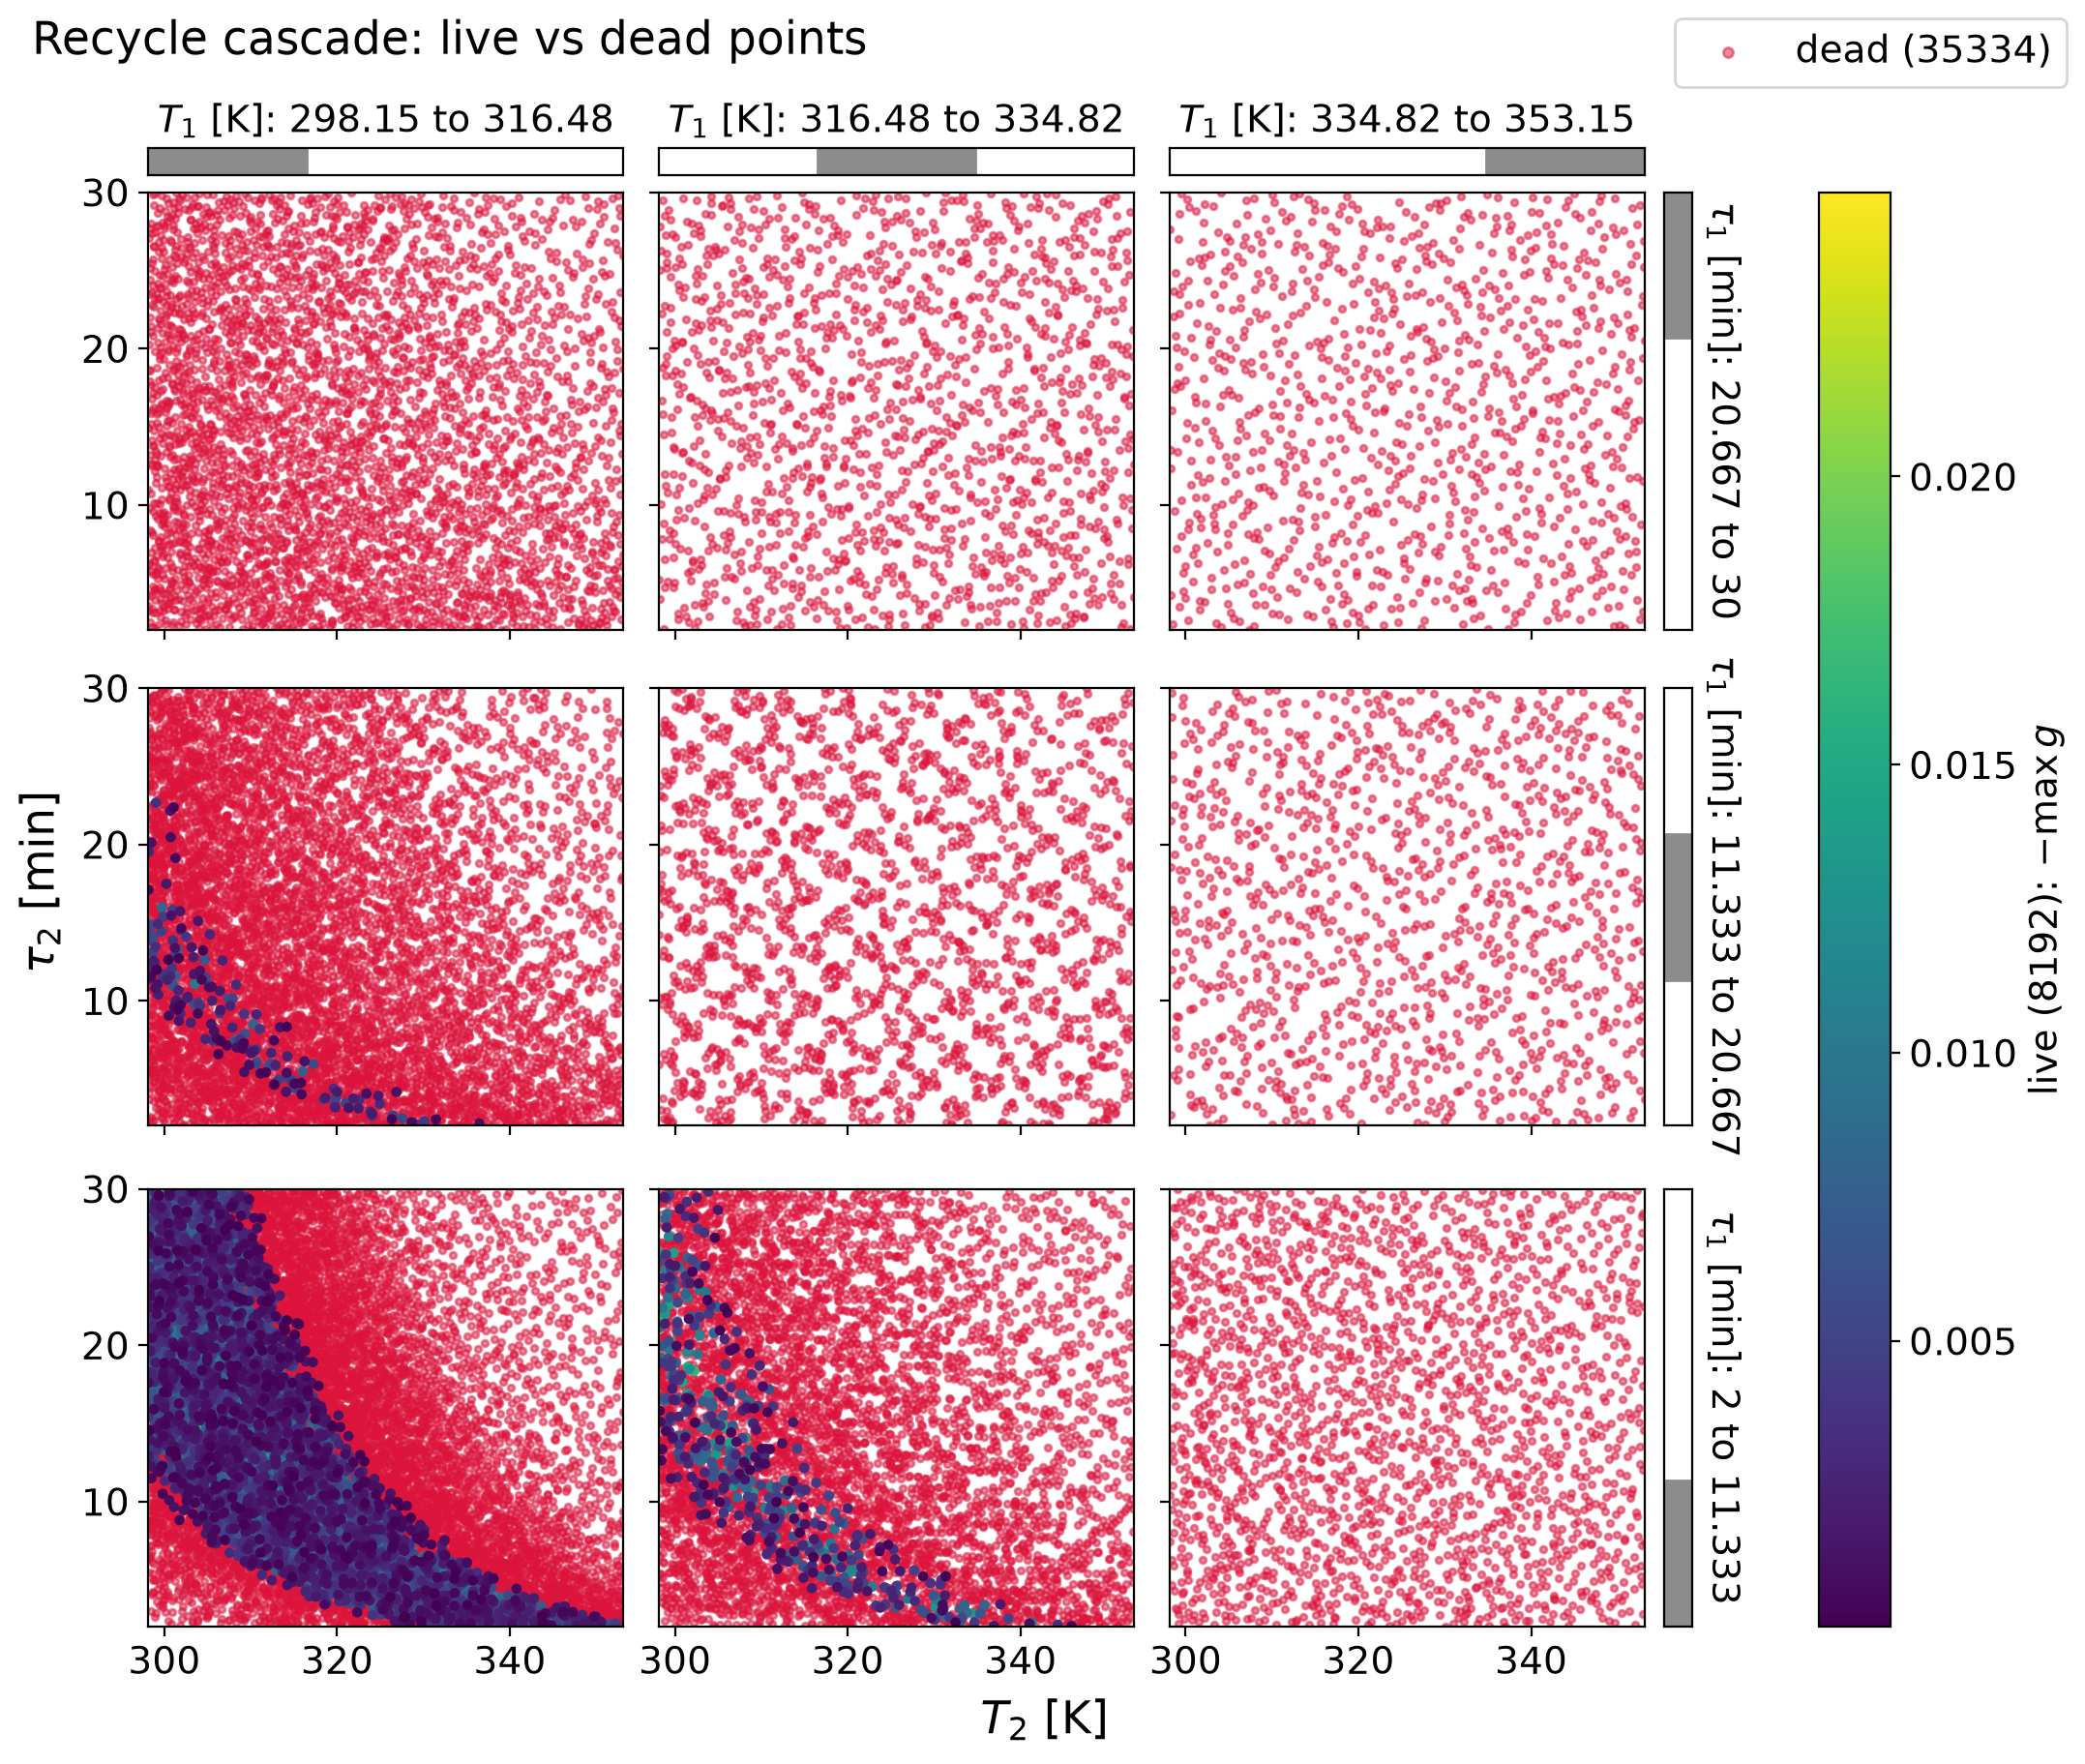

In [17]:
def simultaneous_trellis_plot():
    # NS.livepoints returns: (points[N, nu],  crit[N, 1],  prob[N, 1],  aux[N, 1])
    live_pts, live_feas, *_ = NS_simultaneous.live_points
    dead_pts, dead_feas, *_ = NS_simultaneous.dead_points

    T_1, tau_1, T_2, tau_2 = range(4)
    grid = Trellis(np.linspace(T_LO, T_HI, 4), np.linspace(TAU_LO, TAU_HI, 4),      # bin edges: T_1, tau_1
                   xlabel="$T_2$ [K]", ylabel=r"$\tau_2$ [min]",
                   col_label="$T_1$ [K]", row_label=r"$\tau_1$ [min]",
                   subplot_kw={"xlim": (T_LO, T_HI), "ylim": (TAU_LO, TAU_HI)})
    grid.scatter(dead_pts[:, T_2], dead_pts[:, tau_2], dead_pts[:, T_1], dead_pts[:, tau_1],
                 color="crimson", s=6, alpha=0.5,   label=f"dead ({len(dead_pts)})")
    pcs = grid.scatter(live_pts[:, T_2], live_pts[:, tau_2], live_pts[:, T_1], live_pts[:, tau_1],
                 c=-live_feas.ravel(), s=8)
    grid.colorbar(pcs[0], label=f"live ({len(live_pts)}): $-\\max g$")
    grid.fig.legend(loc="outside upper right")
    grid.fig.suptitle("Recycle cascade: live vs dead points", x=0.01, ha="left")
    save(grid.fig, "Cases/RecycleCascade/trellis_simultaneous")

simultaneous_trellis_plot()

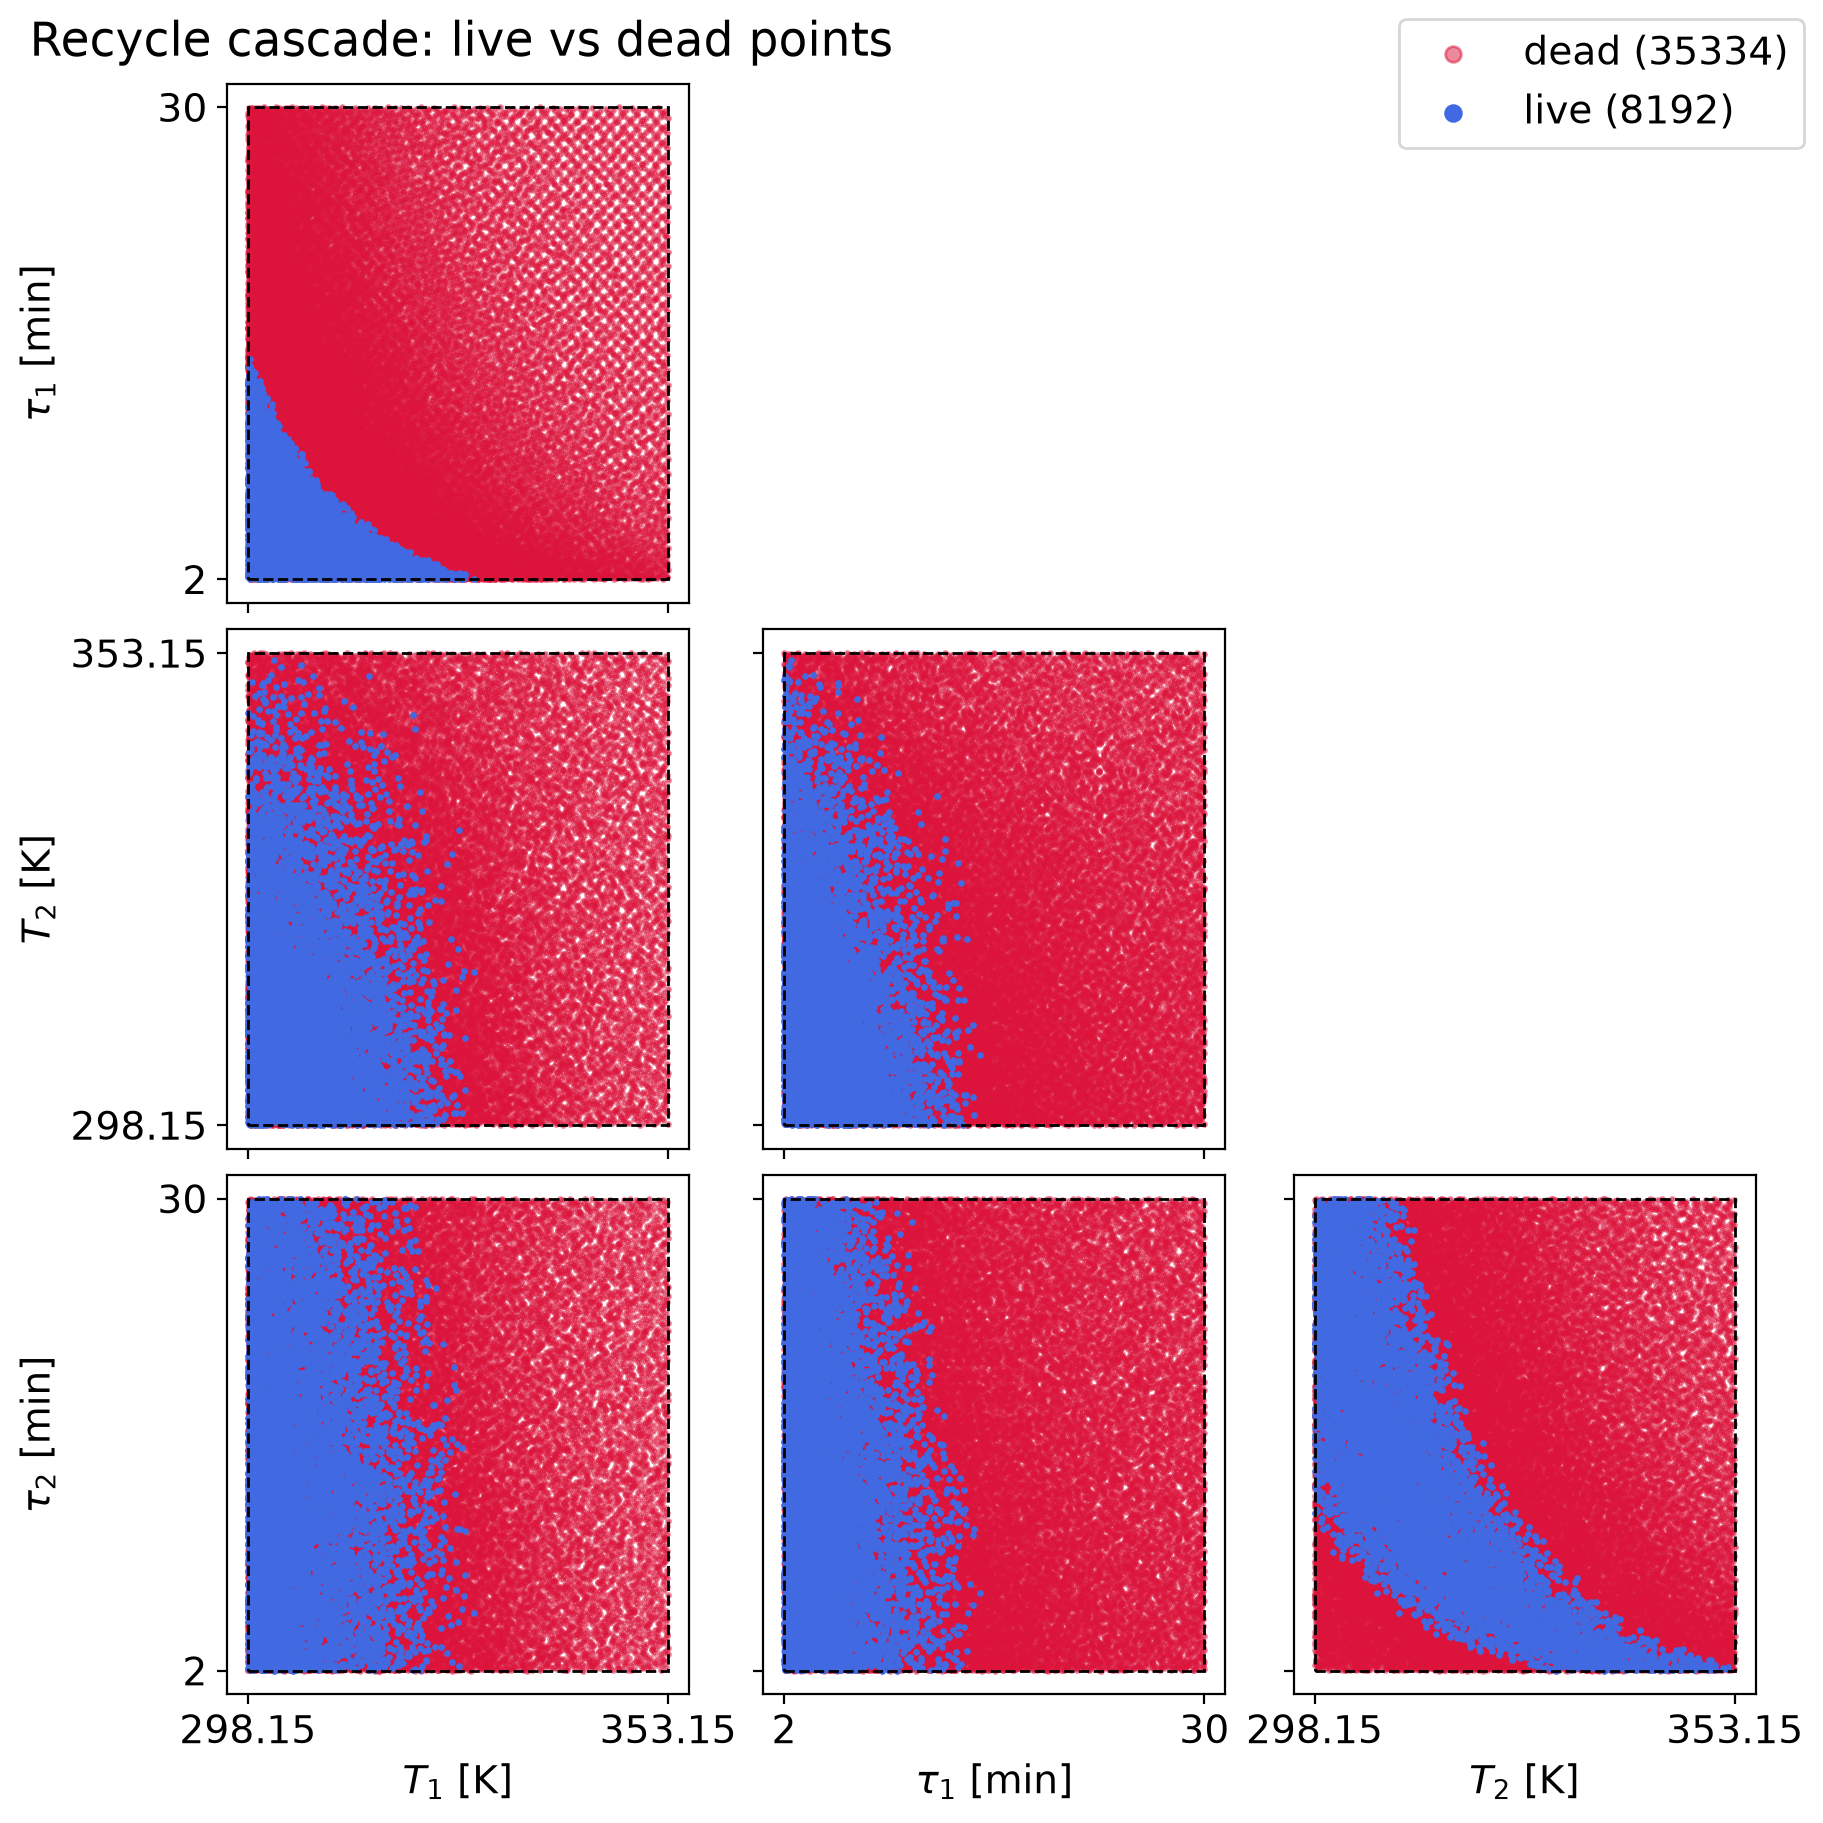

In [18]:
def simultaneous_corner_plot():
    live_pts, live_feas, *_ = NS_simultaneous.live_points
    dead_pts, dead_feas, *_ = NS_simultaneous.dead_points
    grid = Corner([r"$T_1$ [K]", r"$\tau_1$ [min]", r"$T_2$ [K]", r"$\tau_2$ [min]"],
                  [[T_LO, TAU_LO, T_LO, TAU_LO], [T_HI, TAU_HI, T_HI, TAU_HI]])
    # painter's order: dead below, live (feasible) on top
    grid.scatter(dead_pts, s=2, alpha=0.5, color="crimson",   label=f"dead ({len(dead_pts)})")
    grid.scatter(live_pts, s=2, color="royalblue", label=f"live ({len(live_pts)})")
    grid.fig.legend(markerscale=4)
    grid.fig.suptitle("Recycle cascade: live vs dead points", x=0.01, ha="left")
    save(grid.fig, "Cases/RecycleCascade/corner_simultaneous")

simultaneous_corner_plot()

## Decomposition based sampling

### Inlet Bounds Generation

In [19]:
def initialize_search_space():
    k_bounds = np.array([[T_LO, TAU_LO, T_LO, TAU_LO], [T_HI, TAU_HI, T_HI, TAU_HI]]) # T1, tau1, T2, tau2
    v_train = generate_sobol_points(40, k_bounds)
    results, it0 = {}, R1_counter
    r_init = Record_Init()
    for point in v_train:
        T_1, tau_1, T_2, tau_2 = point
        results[tuple(point)] = sim_forward_real(T_1=T_1, tau_1=tau_1, T_2=T_2, tau_2=tau_2, log_obj=r_init)
    num_calls_local = R1_counter - it0
    return results, num_calls_local, r_init
initialization_results, n_iter_init, init_records = initialize_search_space()

In [20]:
def generate_U_hull(infl=0.15):
    """Obtain the minimum and maximum inlet occurences, inflation symmetric by infl"""
    U_hull = {}

    # inlets for M1:
    rho_min, *c_R_min = np.array(init_records.M1_rec_x).min(axis=0)
    rho_max, *c_R_max = np.array(init_records.M1_rec_x).max(axis=0)

    # inlets for R1 (slicing away T1, tau1):
    c_alpha_min =       np.array(init_records.R1_rec_x)[:, -3:].min(axis=0)
    c_alpha_max =       np.array(init_records.R1_rec_x)[:, -3:].max(axis=0)

    # inlets for R2 (slicing away T2, tau2):
    c_R1_min =          np.array(init_records.R2_rec_x)[:, -3:].min(axis=0)
    c_R1_max =          np.array(init_records.R2_rec_x)[:, -3:].max(axis=0)

    # inlets for S1:
    c_R2_min =          np.array(init_records.S1_rec_x).min(axis=0)
    c_R2_max =          np.array(init_records.S1_rec_x).max(axis=0)

    inflate = lambda lo, hi : [np.maximum(lo - infl * (hi - lo), 0), hi + infl * (hi - lo)]
    U_hull["rho"] = inflate(rho_min, rho_max)
    U_hull["c_A_R"] = inflate(c_R_min[0], c_R_max[0])
    U_hull["c_B_R"] = inflate(c_R_min[1], c_R_max[1])
    U_hull["c_C_R"] = inflate(c_R_min[2], c_R_max[2])
    U_hull["c_A_alpha"] = inflate(c_alpha_min[0], c_alpha_max[0])
    U_hull["c_B_alpha"] = inflate(c_alpha_min[1], c_alpha_max[1])
    U_hull["c_C_alpha"] = inflate(c_alpha_min[2], c_alpha_max[2])
    U_hull["c_A_R1"] = inflate(c_R1_min[0], c_R1_max[0])
    U_hull["c_B_R1"] = inflate(c_R1_min[1], c_R1_max[1])
    U_hull["c_C_R1"] = inflate(c_R1_min[2], c_R1_max[2])
    U_hull["c_A_R2"] = inflate(c_R2_min[0], c_R2_max[0])
    U_hull["c_B_R2"] = inflate(c_R2_min[1], c_R2_max[1])
    U_hull["c_C_R2"] = inflate(c_R2_min[2], c_R2_max[2])

    # add manual bounds for Temperature and tau:
    U_hull["T"] = [T_LO, T_HI]
    U_hull["tau"] = [TAU_LO, TAU_HI]

    return U_hull

U_hull = generate_U_hull()

In [21]:
def box(*cols):
    """(2, d) bounds in the given column order, for generate_sobol_points"""
    return np.array([ [U_hull[c][0] for c in cols], 
                      [U_hull[c][1] for c in cols]])


### Sampling Per Unit (Sobol)

In [22]:
# Modeling M1
def generate_train_data_M1():
    """Generates training data for unit M1. Sobol sampling"""
    inputs = generate_sobol_points(n=N_UNIT_OP_SBL, 
                                   bounds=box("rho", "c_A_R", "c_B_R", "c_C_R"))
    c_F = (C_A0, 0, 0)

    records_x = []
    records_y = []

    for x in inputs:
        rho, c_A_R, c_B_R, c_C_R = x
        y = M1(rho=rho, c_R=(c_A_R, c_B_R, c_C_R), c_F=c_F)
        records_x.append(list(x))
        records_y.append(list(y))

    # amend data from initialization phase:
    records_x += init_records.M1_rec_x
    records_y += init_records.M1_rec_y
    return np.array(records_x), np.array(records_y)

M1_training_data = generate_train_data_M1()

In [23]:
# Modeling R1
def generate_train_data_R1():
    """Generates training data for unit R1. Sobol sampling"""
    inputs = generate_sobol_points(n=N_UNIT_OP_SBL, bounds=box("T", "tau", "c_A_alpha", "c_B_alpha", "c_C_alpha"))

    records_x = []
    records_y = []

    for x in inputs:
        T_1, tau_1, c_A_alpha, c_B_alpha, c_C_alpha = x
        k_R1 = compute_k(T_1, 42)[0]
        y = R1((c_A_alpha, c_B_alpha, c_C_alpha), k_R1, tau_1)
        records_x.append(list(x))
        records_y.append(list(y))

    # amend data from initialization phase:
    records_x += init_records.R1_rec_x
    records_y += init_records.R1_rec_y
    return np.array(records_x), np.array(records_y)

R1_training_data = generate_train_data_R1()

In [24]:
# Modeling R2
def generate_train_data_R2():
    """Generates training data for unit R2. Sobol sampling"""
    inputs = generate_sobol_points(n=N_UNIT_OP_SBL, bounds=box("T", "tau", "c_A_R1", "c_B_R1", "c_C_R1"))

    records_x = []
    records_y = []

    for x in inputs:
        T_2, tau_2, c_A_R1, c_B_R1, c_C_R1 = x
        k_R2 = compute_k(42, T_2)[1]
        y = R2((c_A_R1, c_B_R1, c_C_R1), k_R2, tau_2)
        records_x.append(list(x))
        records_y.append(list(y))

    # amend data from initialization phase:
    records_x += init_records.R2_rec_x
    records_y += init_records.R2_rec_y
    return np.array(records_x), np.array(records_y)

R2_training_data = generate_train_data_R2()

In [25]:
# Modeling S1
def generate_train_data_S1():
    """Generates training data for unit S1, based on sobol sampled points within bounds."""
    inputs = generate_sobol_points(n=N_UNIT_OP_SBL, bounds=box("c_A_R2", "c_B_R2", "c_C_R2"))

    records_x = []
    records_y = []

    for x in inputs:
        c_A_R2, c_B_R2, c_C_R2 = x
        y = S1(c_R2=(c_A_R2, c_B_R2, c_C_R2))
        records_x.append(list(x))
        records_y.append(list([*y[0], y[1]]))

    # amend data from initialization phase:
    records_x += init_records.S1_rec_x
    records_y += init_records.S1_rec_y
    return np.array(records_x), np.array(records_y)

S1_training_data = generate_train_data_S1()

### Train ANN Surrogates On Sampled Data Per Unit

width 64 (67 s)   CV rmse/std per width: 4: 0.0225, 8: 0.0075, 16: 0.0037, 32: 0.0029, 64: 0.0025, 128: 0.0026
  c_A_alpha                  0.002    0.05 % of range
  c_B_alpha                  0.002    0.06 % of range
  c_C_alpha                  0.003    0.06 % of range
width 64 (144 s)   CV rmse/std per width: 4: 0.1382, 8: 0.0161, 16: 0.0062, 32: 0.0034, 64: 0.0031, 128: 0.0049
  c_A_R1                     0.005    0.06 % of range
  c_B_R1                     0.004    0.07 % of range
  c_C_R1                     0.006    0.06 % of range
width 64 (258 s)   CV rmse/std per width: 4: 0.1401, 8: 0.0269, 16: 0.0131, 32: 0.0076, 64: 0.0050, 128: 0.0056
  c_A_R2                     0.006    0.09 % of range
  c_B_R2                     0.010    0.11 % of range
  c_C_R2                     0.014    0.08 % of range
width 32 (175 s)   CV rmse/std per width: 4: 0.0823, 8: 0.0209, 16: 0.0074, 32: 0.0046, 64: 0.0051
  c_A_R                      0.010    0.09 % of range
  c_B_R                   

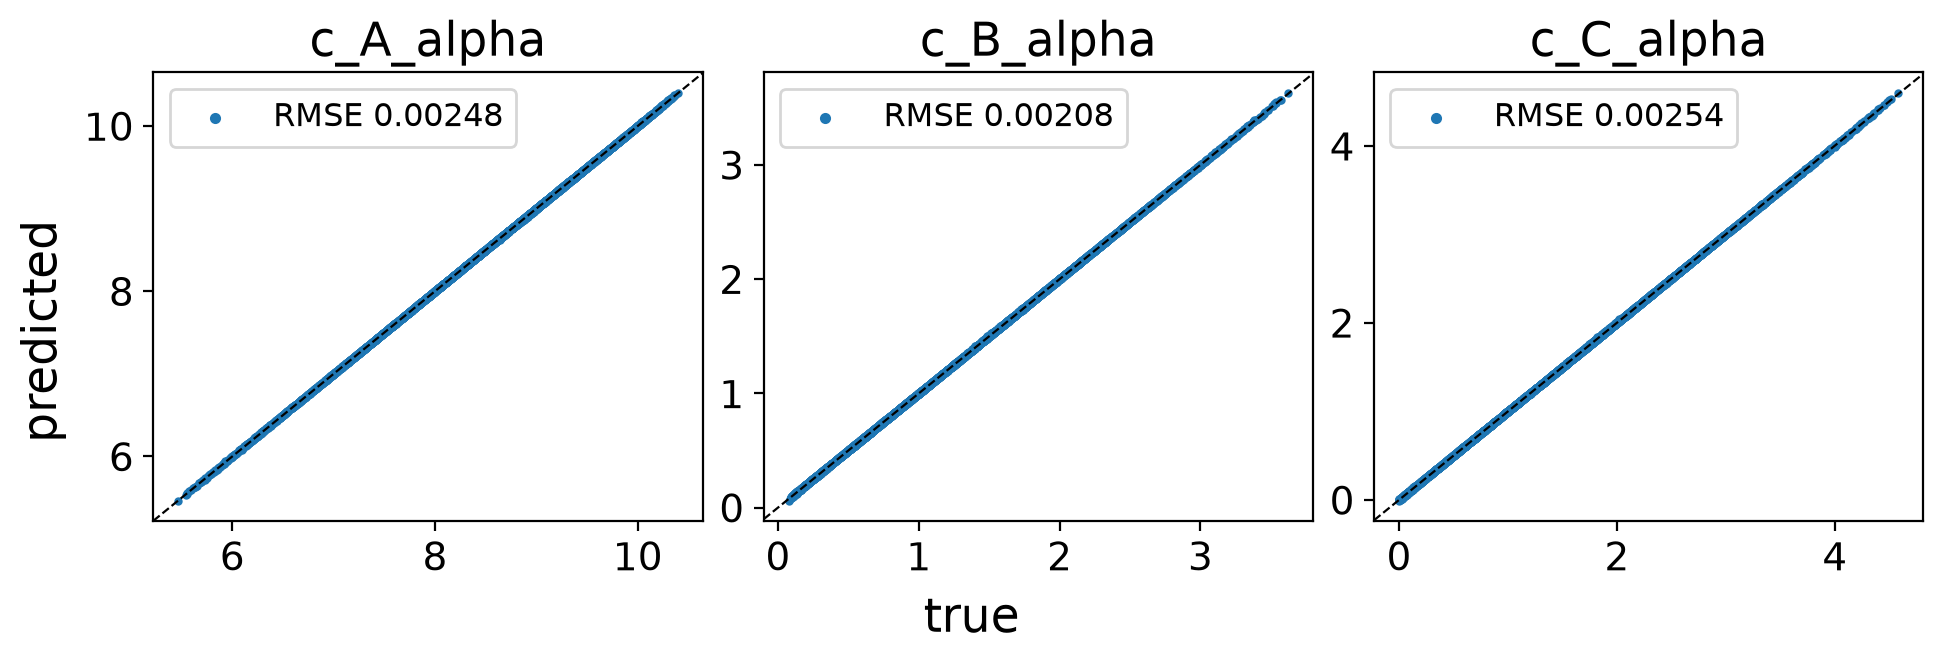

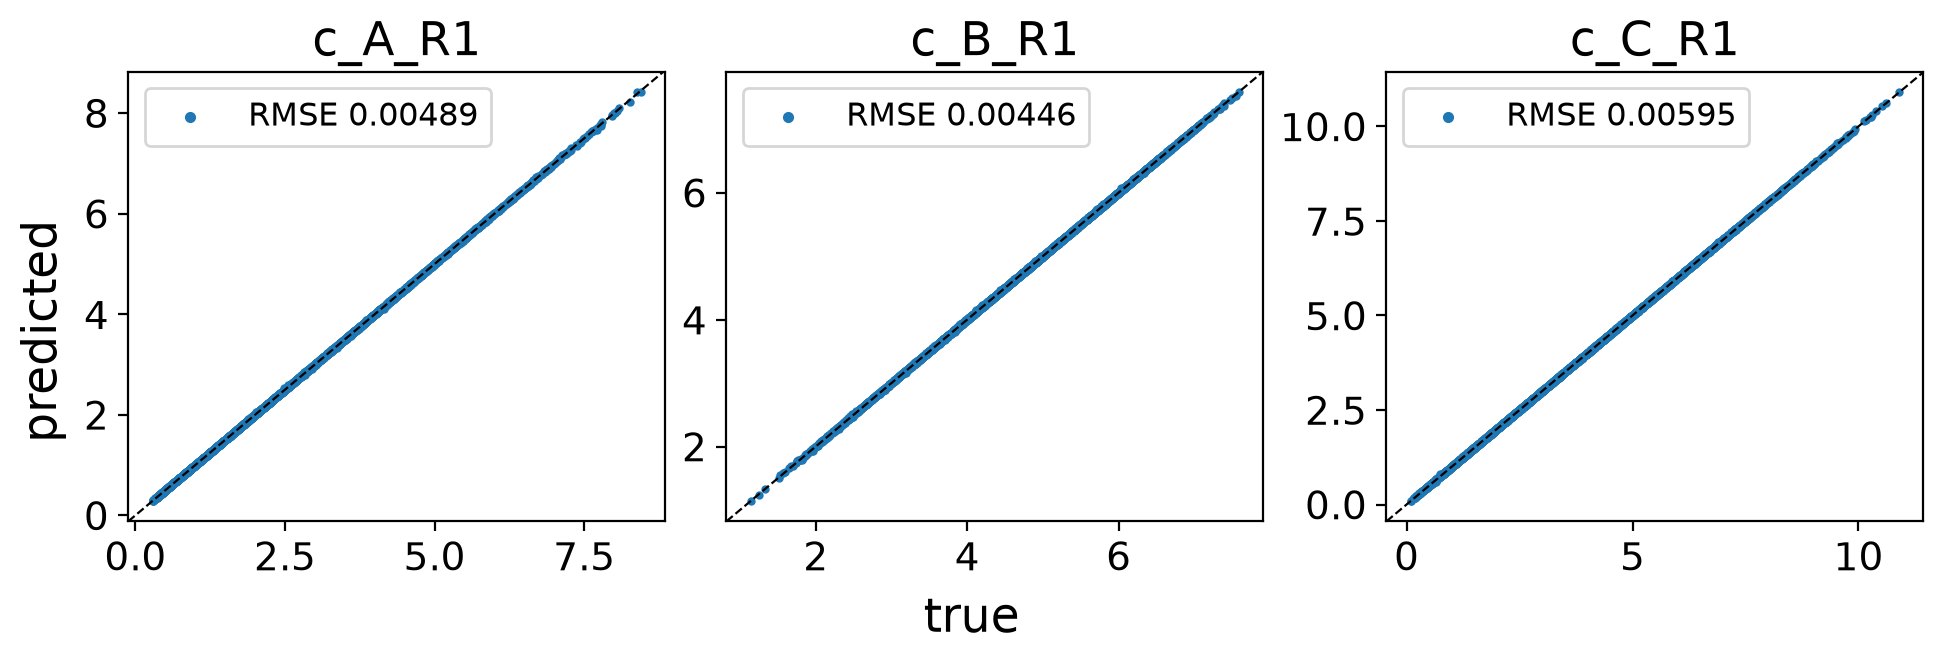

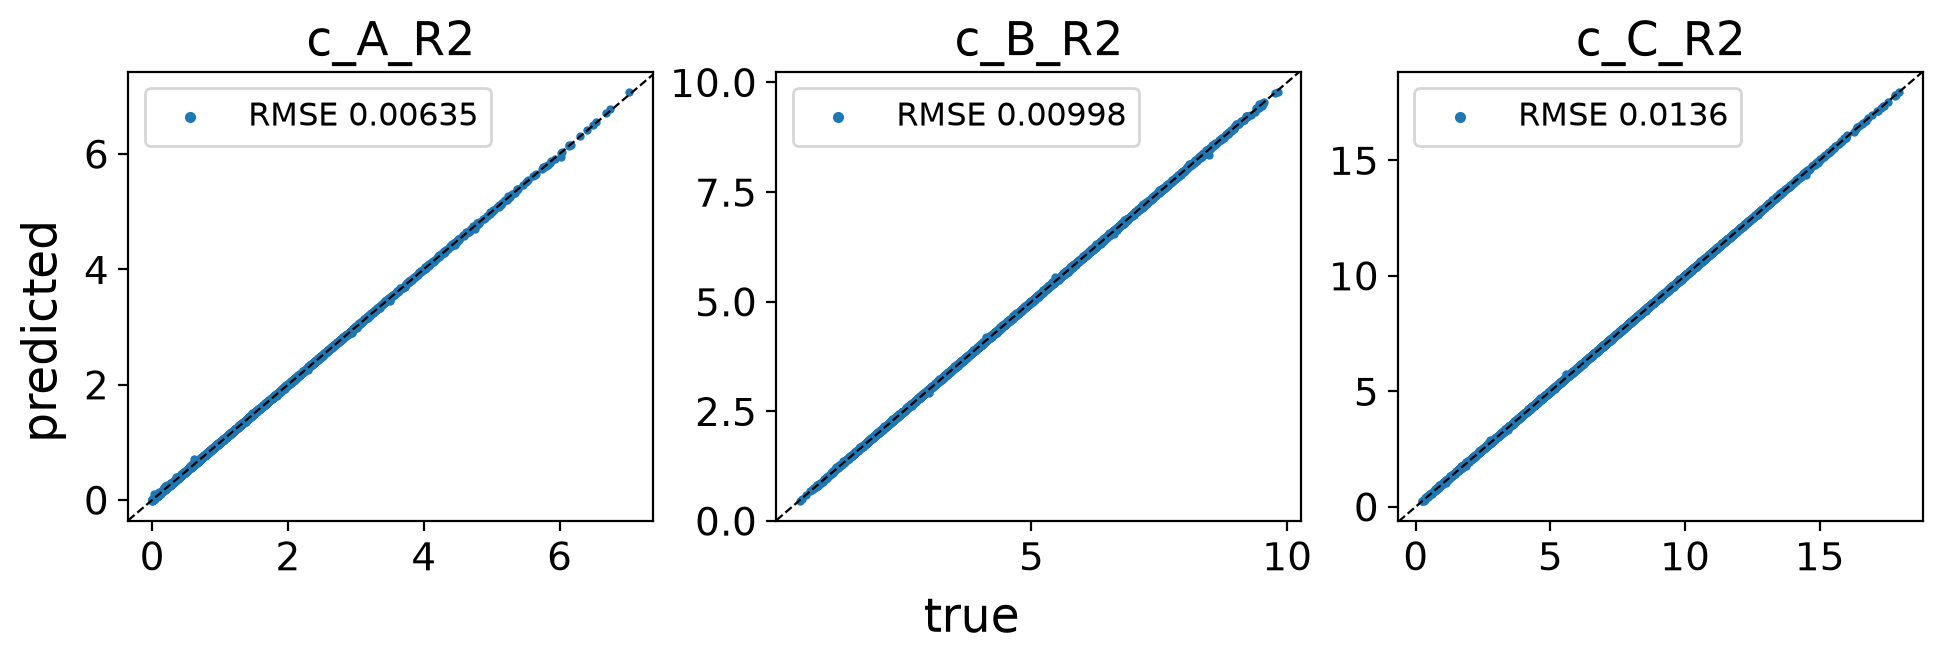

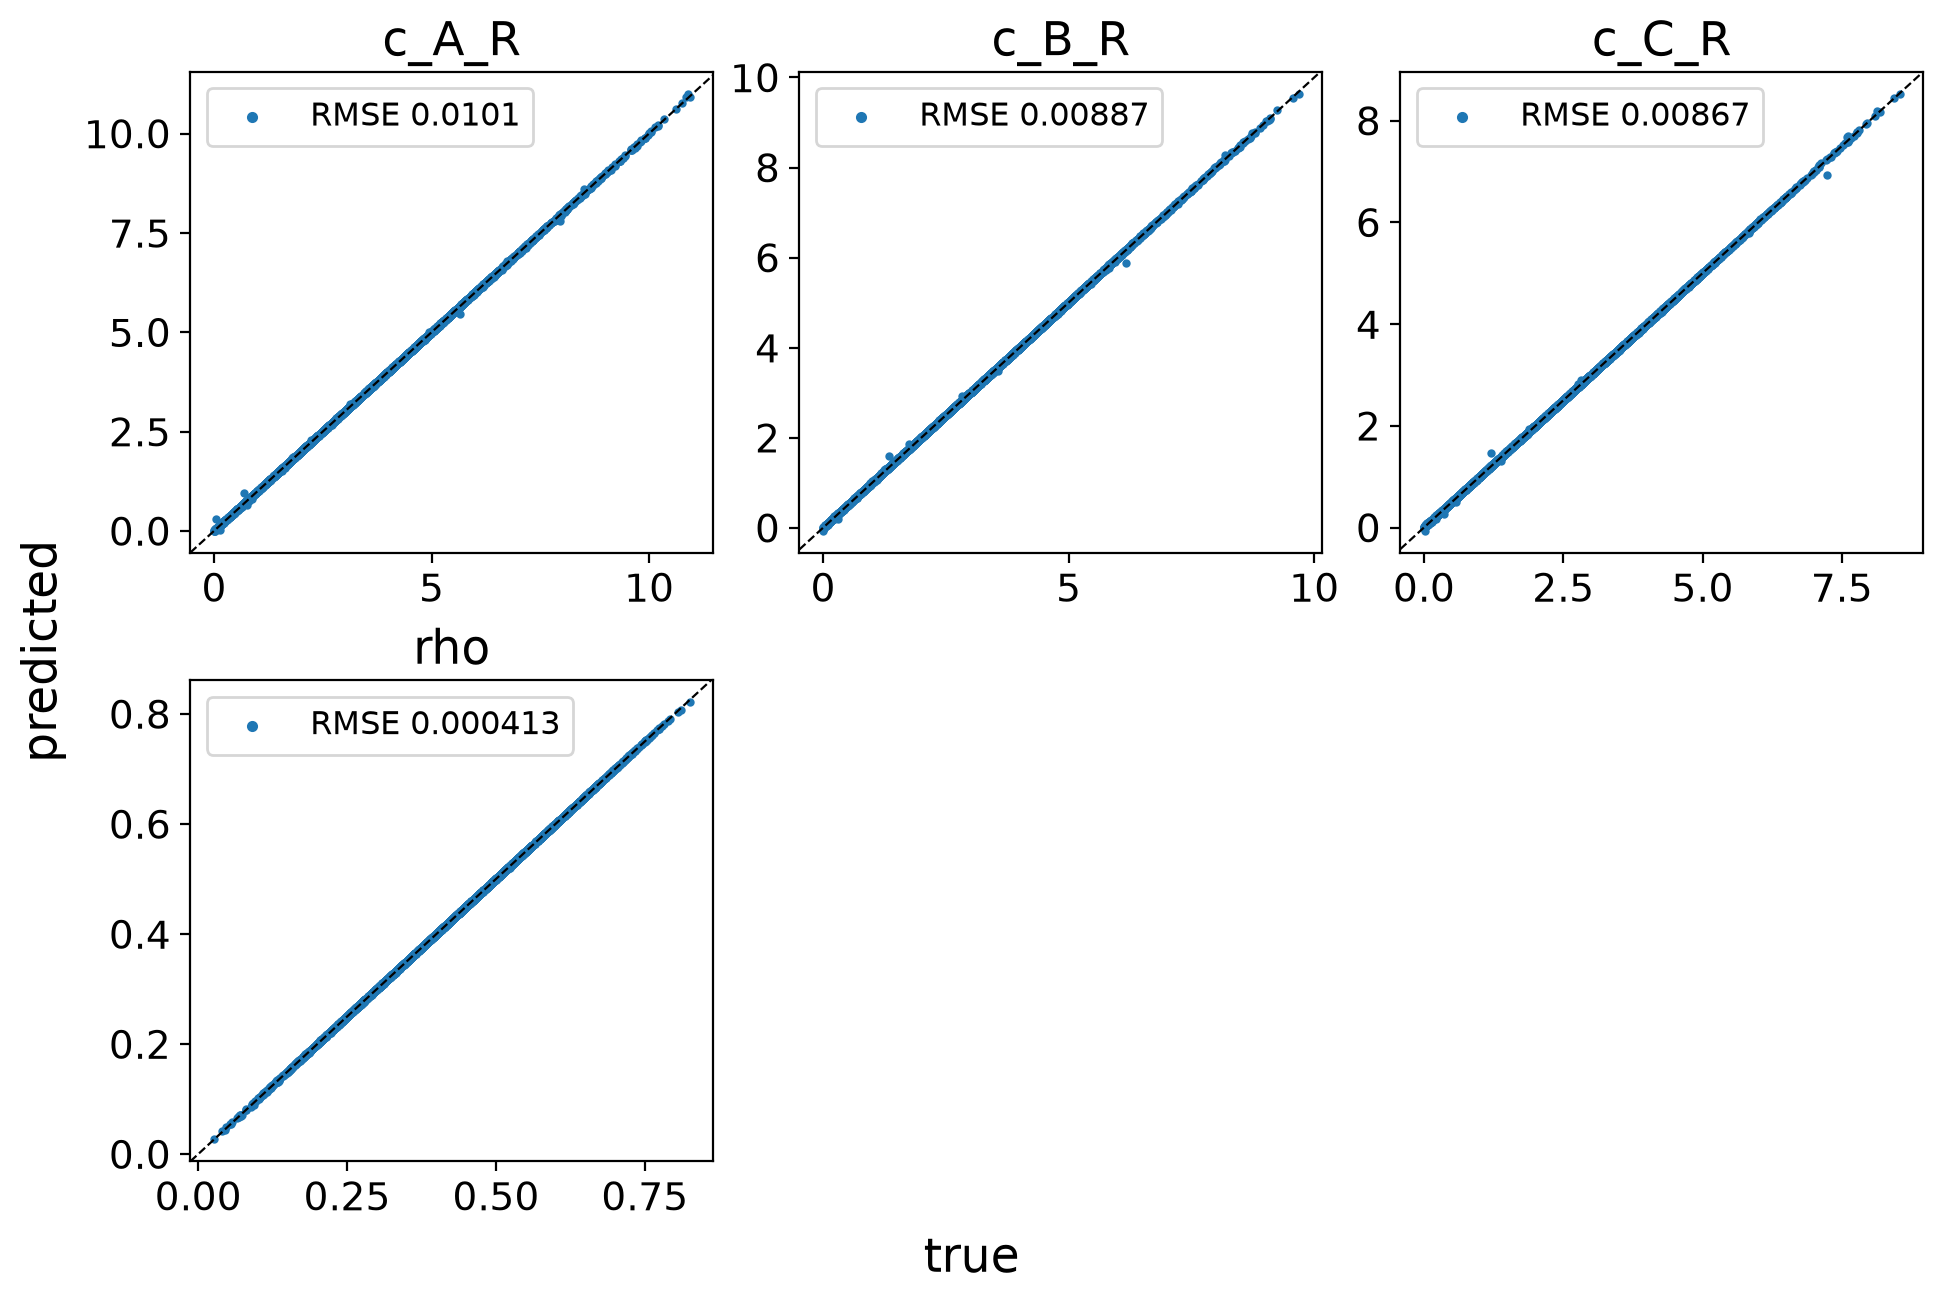

In [26]:
def train_unit(name, data, names):
    surr, _, Y_oof = train_surrogate(*data, names=names, path=f"surr_{name}.txt")
    fig, _ = parity_plot(data[1], Y_oof, names=names)
    save(fig, f"Cases/RecycleCascade/parity_{name}")
    return surr

surr_M1 = train_unit("M1", M1_training_data, names=["c_A_alpha", "c_B_alpha",  "c_C_alpha"])
surr_R1 = train_unit("R1", R1_training_data, names=["c_A_R1", "c_B_R1", "c_C_R1"])
surr_R2 = train_unit("R2", R2_training_data, names=["c_A_R2", "c_B_R2", "c_C_R2"])
surr_S1 = train_unit("S1", S1_training_data, names=["c_A_R", "c_B_R", "c_C_R", "rho"])

In [27]:
# Surrogate version: simulate forward (to be called by Nested Sampler)
def sim_forward_surr(T_1, tau_1, T_2, tau_2):
    it, MAX_ITER = 0, 1000
    c_F = C_A0, 0, 0 # mol/L (pure benzene feed)
    # initial guesses (ig)
    inf_guess = get_informed_guess()
    rho_ig = 0.3 if not inf_guess[0] else inf_guess[1]
    c_R_ig = (5, 2, 1) if not inf_guess[0] else inf_guess[2]

    while (it < MAX_ITER):
        it += 1
        c_alpha = surr_M1((rho_ig, *c_R_ig))
        c_R1 = surr_R1((T_1, tau_1, *c_alpha))
        c_R2 = surr_R2((T_2, tau_2, *c_R1))
        *c_R, rho = surr_S1(c_R2)
        conv = is_converged(guess=[*c_R_ig, rho_ig], real=[*c_R, rho])

        if conv:
            return SimResult(converged=True, c_alpha=c_alpha,
                             c_R1=c_R1, c_R2=c_R2,
                             c_R=c_R, c_F=c_F, rho=rho)

        # update to next tear iteration
        c_R_ig, rho_ig = c_R, rho

    # not converged within MAX_ITER
    return SimResult(False, None, None, None, None, None, None)

In [28]:
# Interface Adapter for surrogate unit operations
def model_simultaneous_surr(x):
    """
    Model of CSTR-cascade flowsheet using surrogate unit operations.
    """
    T_1, tau_1, T_2, tau_2 = x[0], x[1], x[2], x[3]
    sim_res = sim_forward_surr(T_1=T_1, tau_1=tau_1, T_2=T_2, tau_2=tau_2)

    if not sim_res.converged or sim_res.rho < 0 or sim_res.rho > 1:
        # return *something* guaranteed to be infeasible
        return [-1e-8, -1e-8, -1e-8, -1e-8, -1e-8, -1e-8]
    c_A_R1, c_B_R1, c_C_R1 = sim_res.c_R1
    c_A_R2, c_B_R2, c_C_R2 = sim_res.c_R2

    return [c_A_R1, c_A_R2, c_B_R1, c_B_R2, c_C_R1, c_C_R2]

In [29]:
NS_simultaneous_surr = simultaneous_NS(model_simultaneous_surr, 
                                       numlive=N_FEAS_REQ * 2, 
                                       numprop=512)


** INITIALIZING LIVE POINTS (16384)      8.57 SEC

Iterate        Contour #Feas    #Dead         Factor
----------------------------------------------------
      0     7.6751e-01   206        0     3.0000e-01
     25     3.1768e-01   378     9456     2.6730e-01
     50     2.1656e-01   555    15436     2.4848e-01
     75     1.6391e-01   735    19798     2.3560e-01
    100     1.3193e-01   909    23235     2.2592e-01
    125     1.1123e-01  1075    26067     2.1824e-01
    150     9.5826e-02  1251    28547     2.1173e-01
    175     8.3743e-02  1447    30794     2.0600e-01
    200     7.4580e-02  1621    32784     2.0106e-01
    225     6.7085e-02  1809    34612     1.9662e-01
    250     6.1039e-02  1989    36276     1.9267e-01
    275     5.5628e-02  2187    37807     1.8910e-01
    300     5.1067e-02  2393    39268     1.8576e-01
    325     4.6718e-02  2616    40745     1.8244e-01
    350     4.3168e-02  2831    42004     1.7966e-01
    375     3.8477e-02  3144    43820     1.757

In [30]:
surr_candidates = NS_simultaneous_surr.live_points[0]

In [31]:
def constraints_satisfied(c_R1: tuple, c_R2: tuple) -> bool:
    c_A_R1, c_B_R1, c_C_R1 = c_R1
    c_A_R2, c_B_R2, c_C_R2 = c_R2
    g1 = c_C_R1 / (c_A_R1 + c_B_R1 + c_C_R1) - DCB_FRACTION_CAP <= 0
    g2 = MCB_FLOOR - c_B_R2 / (c_A_R2 + c_B_R2 + c_C_R2)        <= 0 
    g3 = CONV_FLOOR - (1 - c_A_R2 / C_A0)                       <= 0
    if g1 and g2 and g3:
        return True
    return False

In [32]:
def surrogate_candidate_validation(n_req=N_FEAS_REQ):
    """
    Validates the surrogate candidates on the real flowsheet until n_req are
    feasible. Returns the feasible designs, the number of candidates verified
    and the tear iterations spent.
    """
    true_feas_set, n_verified, it0 = [], 0, R1_counter
    # NOTE: live points are sorted by margin, so using the first N_FEAS_REQ candidates in order
    # selects the deepest ones and under-samples the boundary (bands were observed). Shuffling
    # avoids this; the price is a random subset, which drops some boundary points.
    surr_candidates_shuffled = np.random.default_rng(seed=42).permutation(surr_candidates, axis=0)
    for cand in surr_candidates_shuffled:
        if len(true_feas_set) >= n_req:
            break
        n_verified += 1
        sim_res = sim_forward_real(*cand)
        if sim_res.converged and constraints_satisfied(c_R1=sim_res.c_R1, c_R2=sim_res.c_R2):
            true_feas_set.append(cand)
    num_calls_local = R1_counter - it0
    return true_feas_set, n_verified, num_calls_local

validated_candidates, n_verified, n_iter_val = surrogate_candidate_validation()

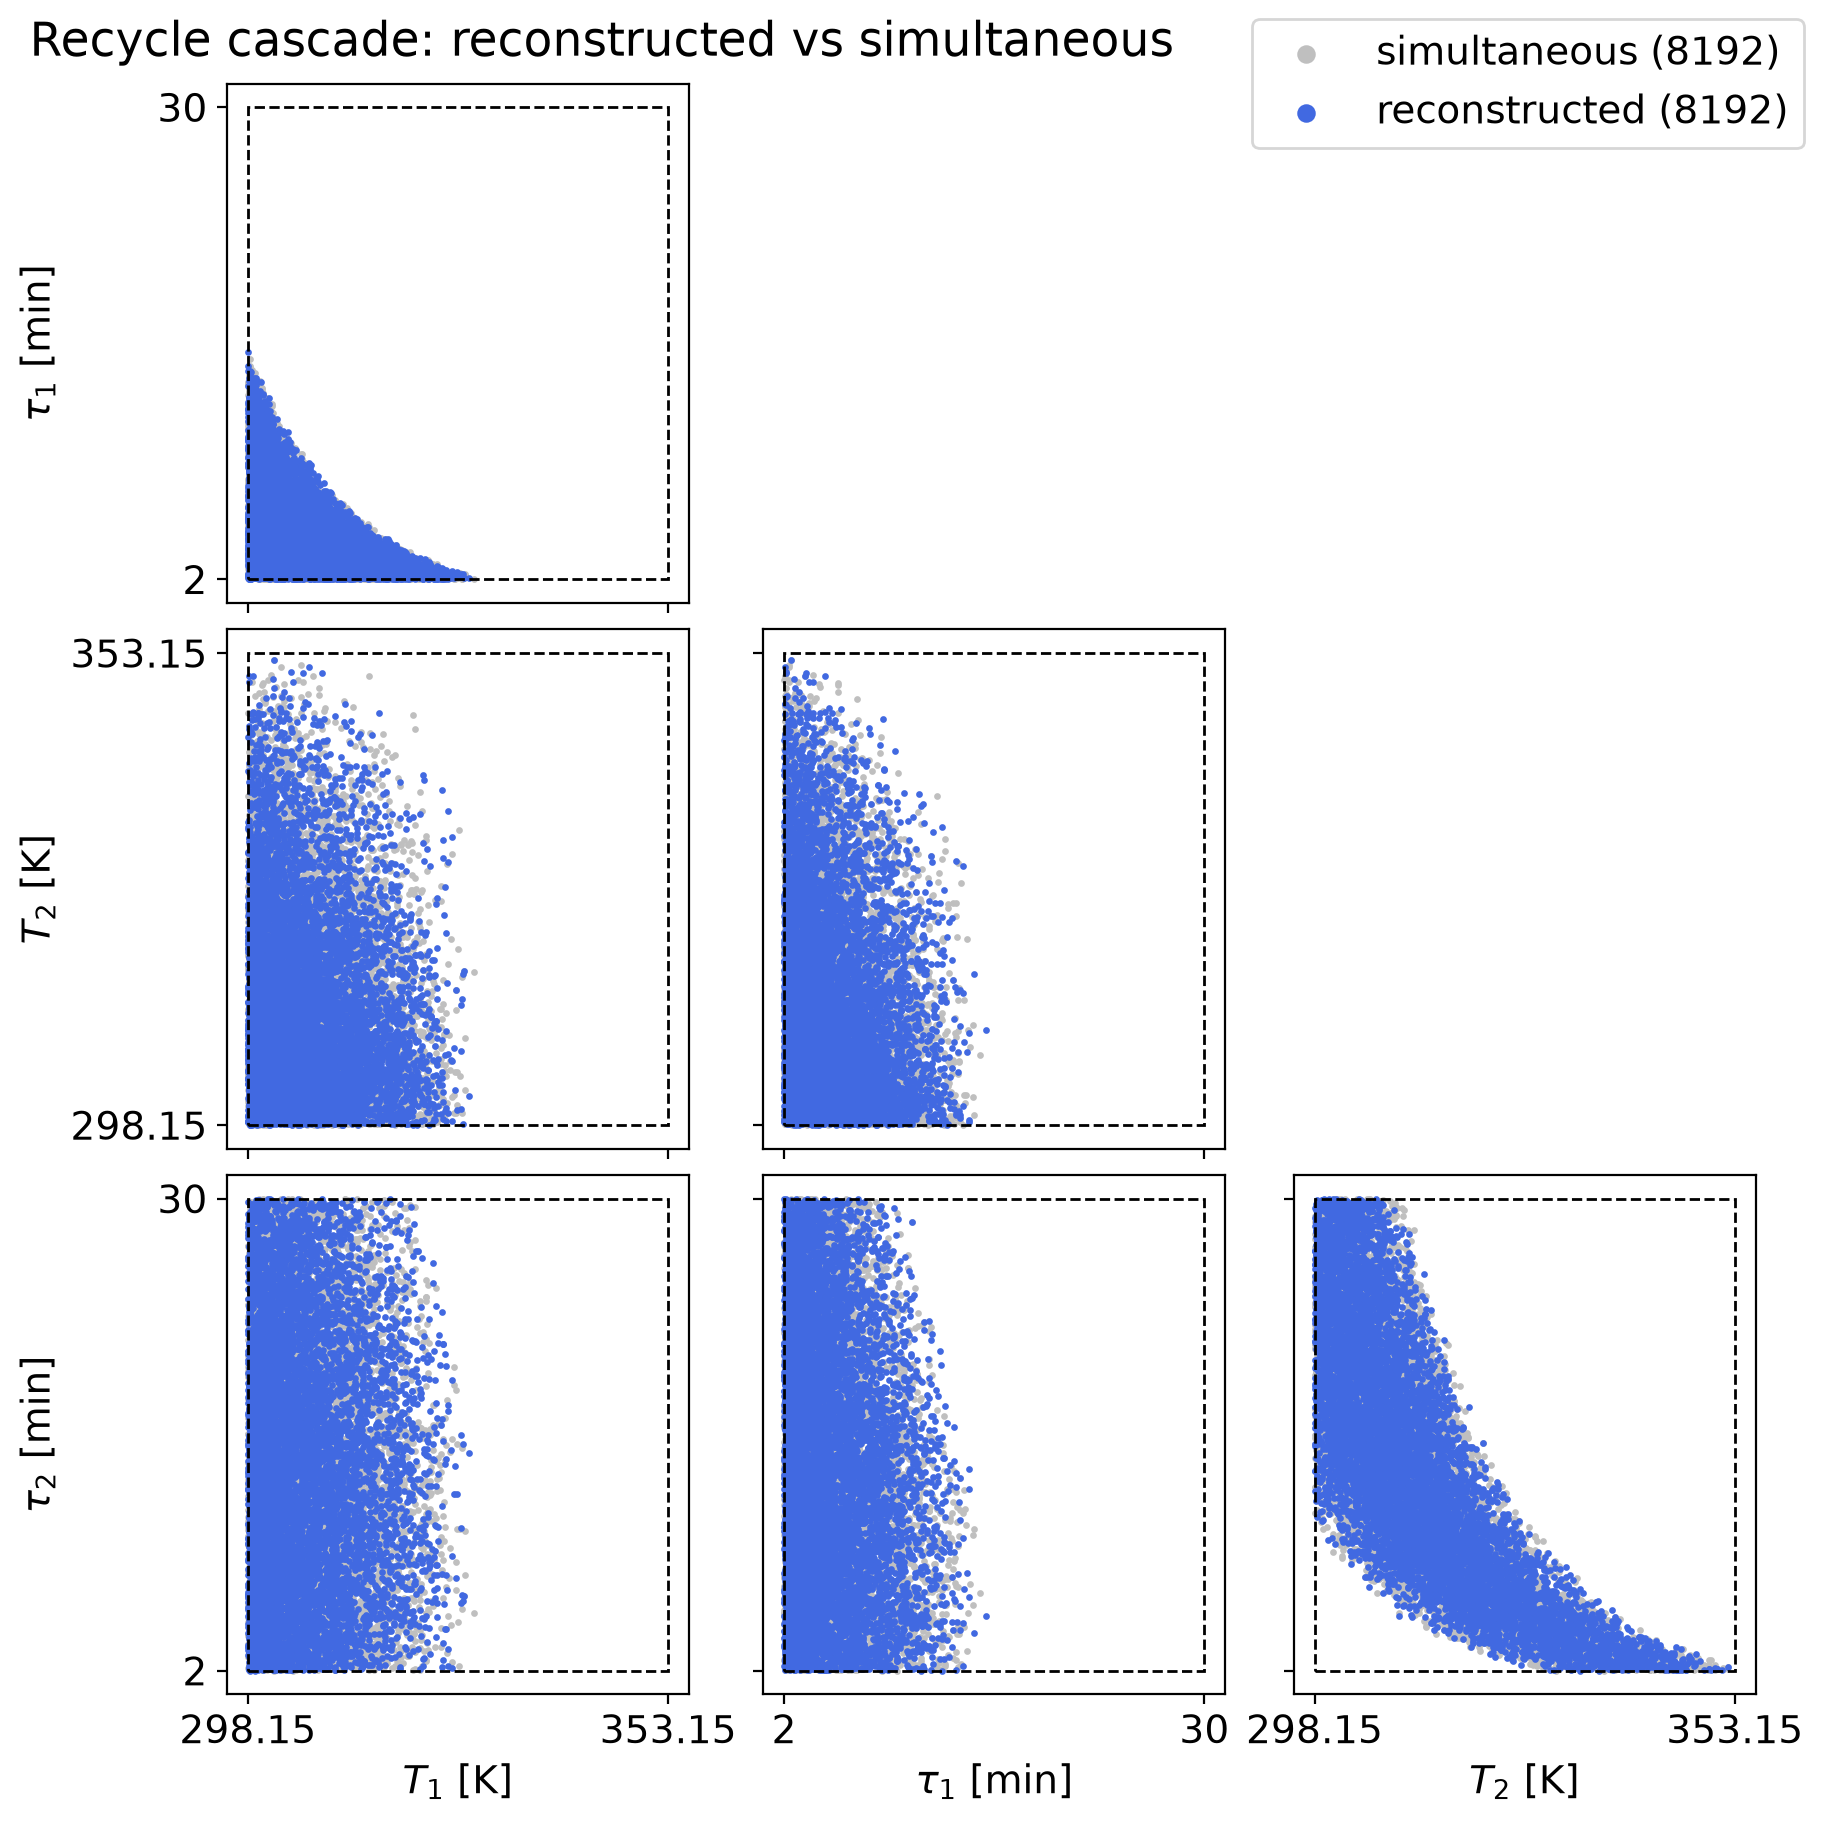

In [33]:
def simultaneous_reconstructed_corner_plot():
    live_pts = np.array(validated_candidates)
    live_pts_simult, *_ = NS_simultaneous.live_points
    grid = Corner([r"$T_1$ [K]", r"$\tau_1$ [min]", r"$T_2$ [K]", r"$\tau_2$ [min]"],
                  [[T_LO, TAU_LO, T_LO, TAU_LO], [T_HI, TAU_HI, T_HI, TAU_HI]])
    grid.scatter(live_pts_simult, s=2, color="0.75", label=f"simultaneous ({len(live_pts_simult)})")
    grid.scatter(live_pts, s=2, color="royalblue",   label=f"reconstructed ({len(live_pts)})")
    grid.fig.legend(markerscale=4)
    grid.fig.suptitle("Recycle cascade: reconstructed vs simultaneous", x=0.01, ha="left")
    save(grid.fig, "Cases/RecycleCascade/corner_reconstructed")

simultaneous_reconstructed_corner_plot()

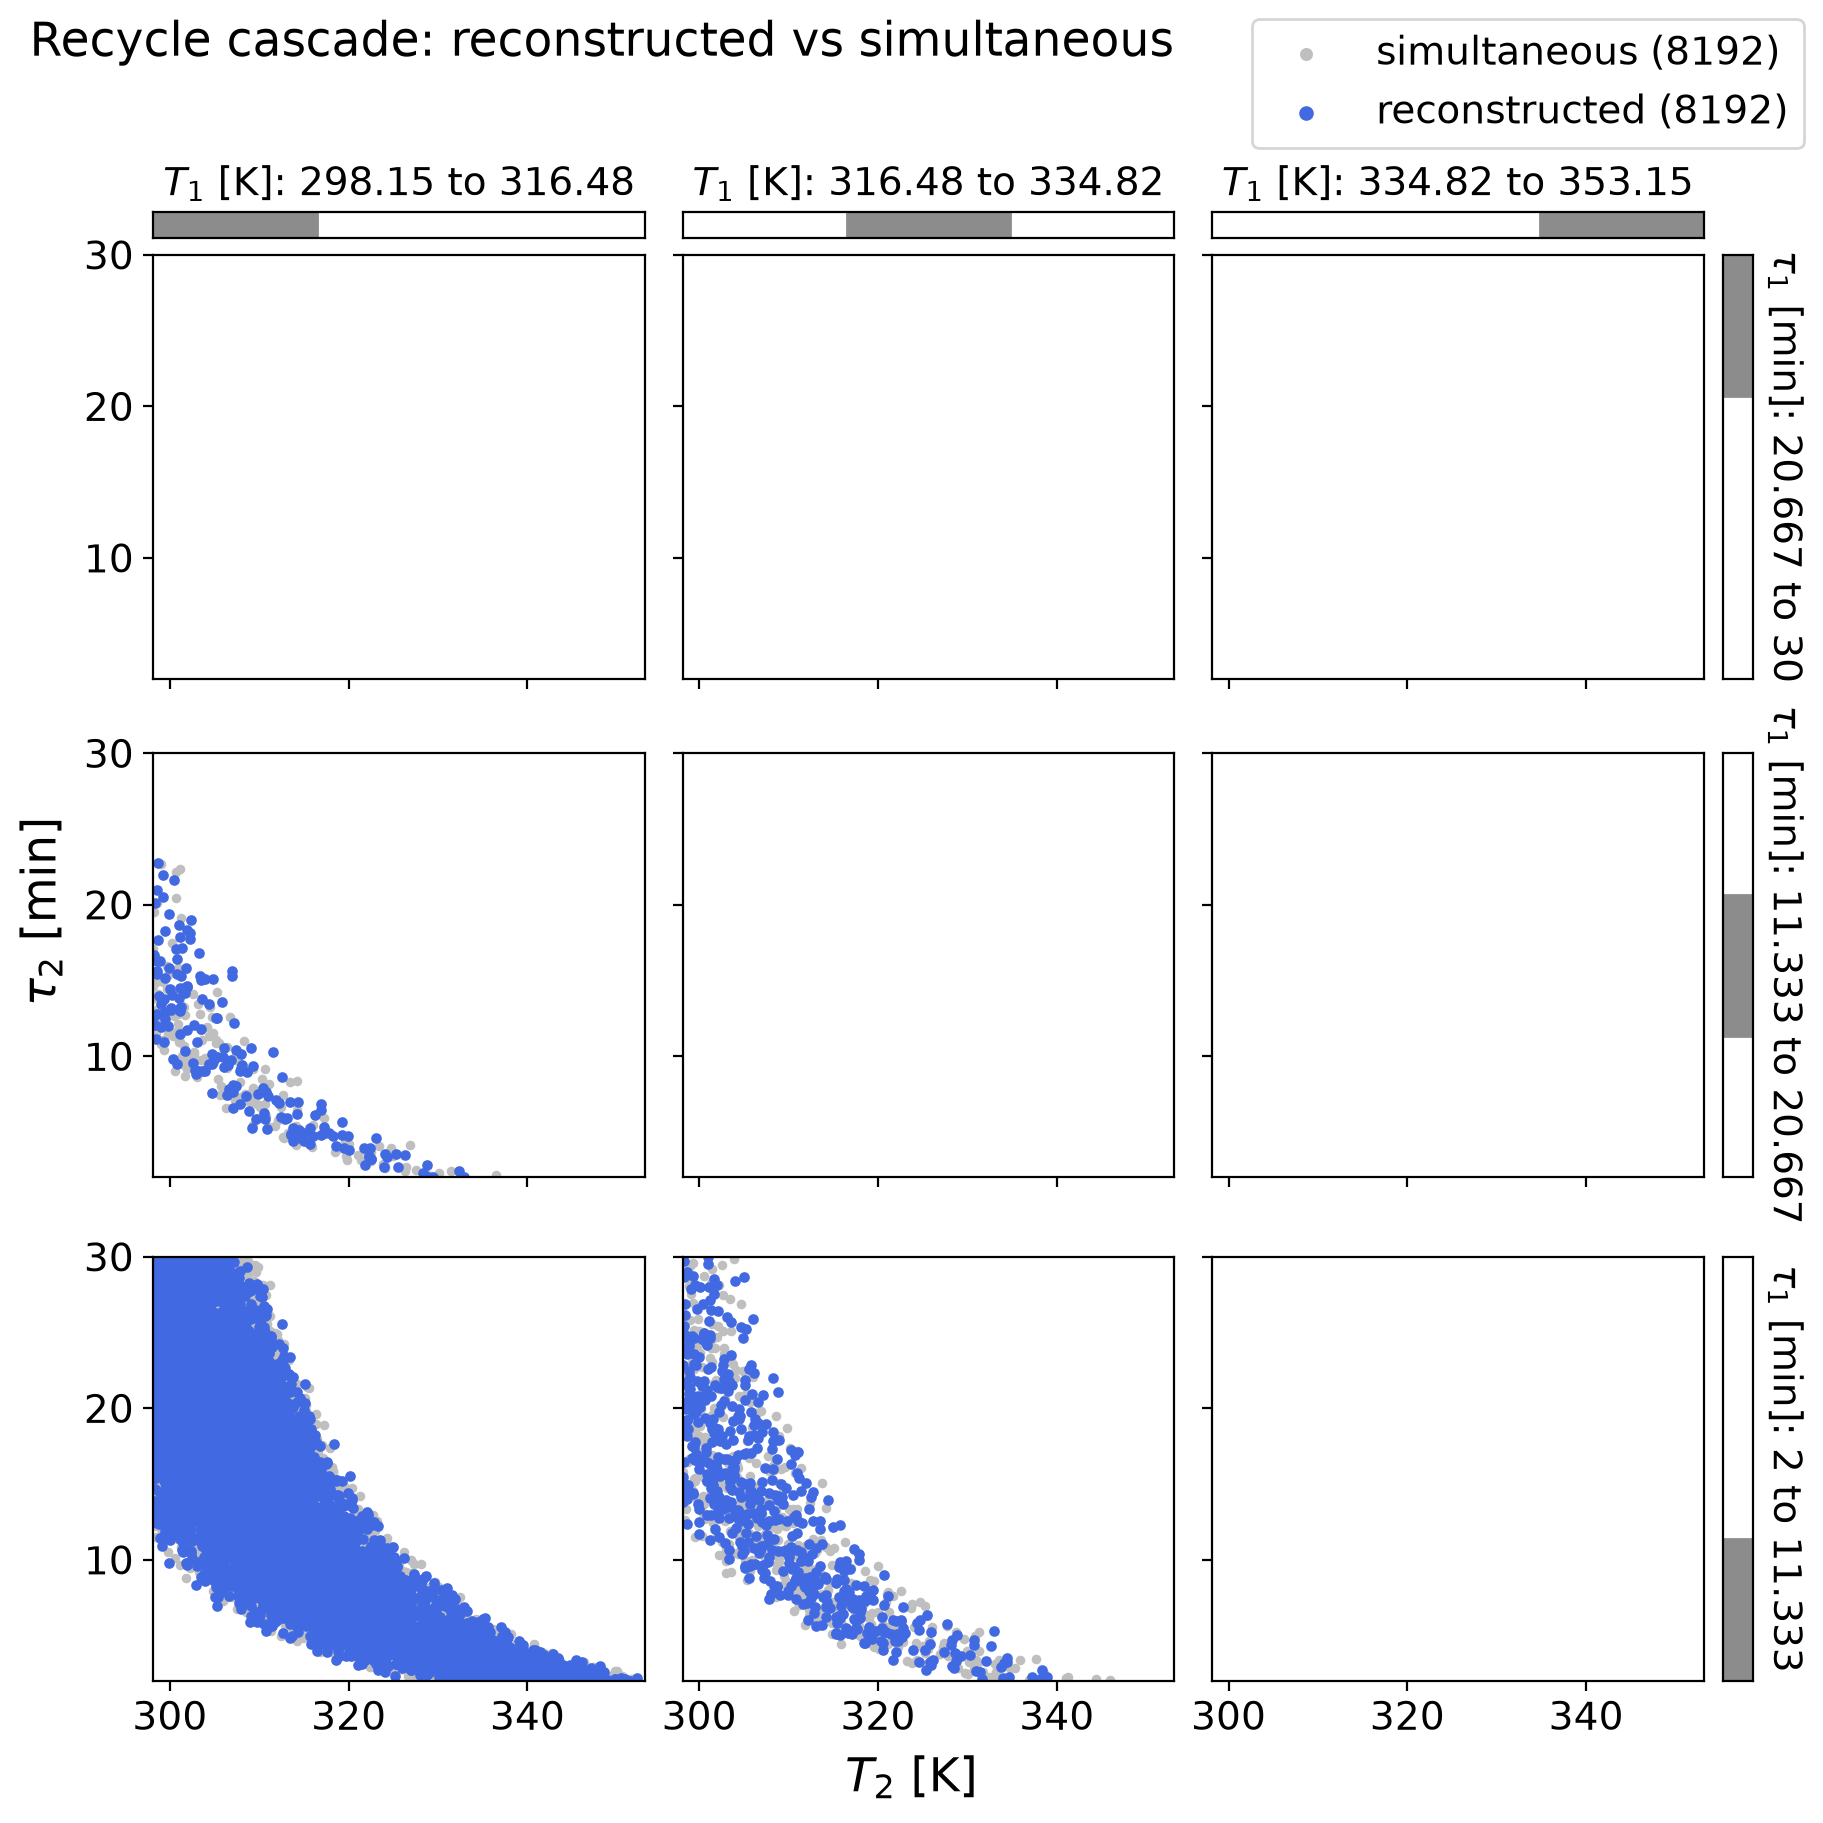

In [34]:
def simultaneous_reconstructed_trellis_plot():
    rec_pts = np.array(validated_candidates)
    sim_pts, *_ = NS_simultaneous.live_points
    T_1, tau_1, T_2, tau_2 = range(4)
    grid = Trellis(np.linspace(T_LO, T_HI, 4), np.linspace(TAU_LO, TAU_HI, 4),      # bin edges: T_1, tau_1
                   xlabel="$T_2$ [K]", ylabel=r"$\tau_2$ [min]",
                   col_label="$T_1$ [K]", row_label=r"$\tau_1$ [min]",
                   subplot_kw={"xlim": (T_LO, T_HI), "ylim": (TAU_LO, TAU_HI)})
    grid.scatter(sim_pts[:, T_2], sim_pts[:, tau_2], sim_pts[:, T_1], sim_pts[:, tau_1], color="0.75", s=6, label=f"simultaneous ({len(sim_pts)})")
    grid.scatter(rec_pts[:, T_2], rec_pts[:, tau_2], rec_pts[:, T_1], rec_pts[:, tau_1], color="royalblue", s=8, label=f"reconstructed ({len(rec_pts)})")
    grid.fig.legend(loc="outside upper right")
    grid.fig.suptitle("Recycle cascade: reconstructed vs simultaneous", x=0.01, ha="left")
    save(grid.fig, "Cases/RecycleCascade/trellis_reconstructed")

simultaneous_reconstructed_trellis_plot()


In [35]:
print("M1:", M1_counter, "R1:", R1_counter, "R2:", R2_counter, "S1:", S1_counter)

M1: 47583 R1: 47583 R2: 47583 S1: 47583


In [36]:
def benchmark():
    """comparison of simultaneous and decomposed results in flowsheet equivalents (EQ):
    1 EQ = one evaluation of the real flowsheet = (mean tear iterations) x (one call of each unit)"""
    n_eval_simult = NS_simultaneous.stats.numfct
    iters_per_eval = n_iter_sim / n_eval_simult
    eq = lambda n_iter: n_iter / iters_per_eval
    # training: N_UNIT_OP_SBL samples per unit = N_UNIT_OP_SBL calls of each of the four units
    cost_init, cost_train, cost_valid = eq(n_iter_init), eq(N_UNIT_OP_SBL), eq(n_iter_val)
    cost_dec = cost_init + cost_train + cost_valid
    print(f"decomposition: {cost_dec:.0f} EQ (initialisation {cost_init:.0f}, training {cost_train:.0f}, "
          f"verification {cost_valid:.0f} for {n_verified} candidates; "
          f"surrogate sampling {NS_simultaneous_surr.stats.numfct} evaluations at no flowsheet cost)")
    print(f"true feasible rate {100 * len(validated_candidates) / n_verified:.2f} %")
    print(f"simultaneous {n_eval_simult} EQ ({iters_per_eval:.2f} tear iterations per evaluation)")
    print(f"reduction: {100 * (1 - cost_dec / n_eval_simult):.1f} %")
    print(f"cost ratio: {(n_eval_simult / cost_dec):.1f} (#simultaneous / #decomposed)")

benchmark()

decomposition: 9427 EQ (initialisation 40, training 811, verification 8576 for 8382 candidates; surrogate sampling 386560 evaluations at no flowsheet cost)
true feasible rate 97.73 %
simultaneous 178432 EQ (5.05 tear iterations per evaluation)
reduction: 94.7 %
cost ratio: 18.9 (#simultaneous / #decomposed)


In [37]:
def get_fraction_of_surrogate_true_feasibility():
    """
    Computes the fraction of the points suggested feasible by the
    surrogate flowsheet, that are actually feasible on real flowsheet
    """
    counter = 0
    for cand in surr_candidates:
        sim_res = sim_forward_real(*cand)
        if (sim_res.converged):
            if (constraints_satisfied(c_R1=sim_res.c_R1, c_R2=sim_res.c_R2)):
                counter += 1

    print(f"true feasible: {100 * (counter/len(surr_candidates)):.2f} %")
                

get_fraction_of_surrogate_true_feasibility()

true feasible: 97.71 %
